[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/therestiscode/notebooks/blob/main/02-uint8-wrap/brighten.ipynb)

# I brightened a photo. The sky went black.

Adding a number to an image does not brighten the bright pixels. It wraps them,
and NumPy does not say a word about it.

Run the cells in order. Nothing here is simulated — it is the same photo and the
same arithmetic as the short.


## The photo


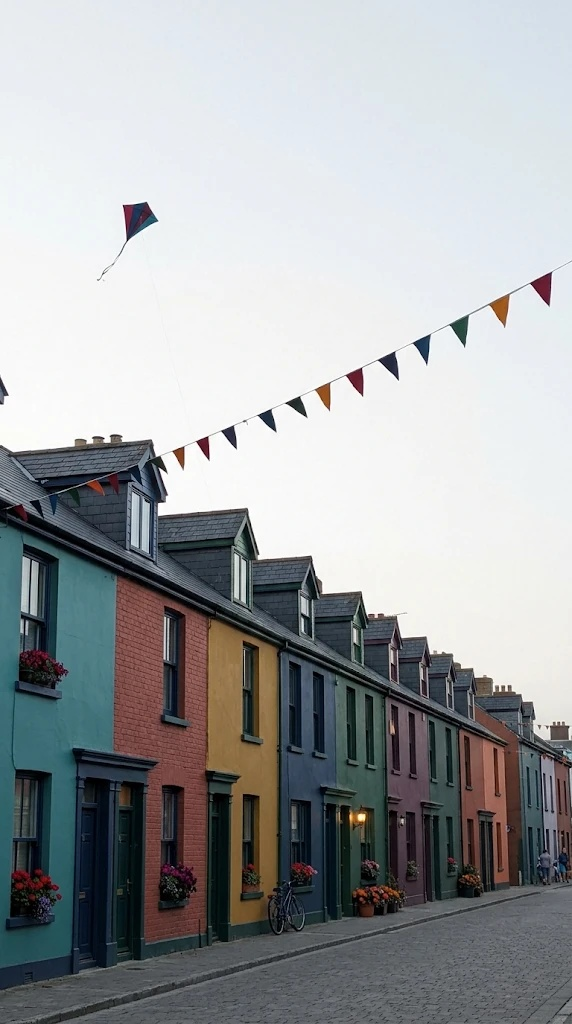

In [1]:
import os
import urllib.request
import numpy as np
import PIL.Image

# In Colab the photo is not next to the notebook, so fetch it once.
if not os.path.exists("sky.jpeg"):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/therestiscode/notebooks/main/02-uint8-wrap/sky.jpeg", "sky.jpeg")

photo = np.array(PIL.Image.open("sky.jpeg").convert("RGB"))
PIL.Image.fromarray(photo)


An ordinary photograph. Here is the only thing about it that matters:


In [2]:
print("shape        ", photo.shape)
print("dtype        ", photo.dtype)
print("a byte holds ", np.iinfo(np.uint8).min, "to", np.iinfo(np.uint8).max)
print("darkest      ", photo.min())
print("brightest    ", photo.max())


shape         (1024, 572, 3)
dtype         uint8
a byte holds  0 to 255
darkest       0
brightest     255


`uint8` — an unsigned 8-bit integer. One byte per channel, per pixel.
It counts from 0 to 255 and it cannot hold 256.


## Brighten it


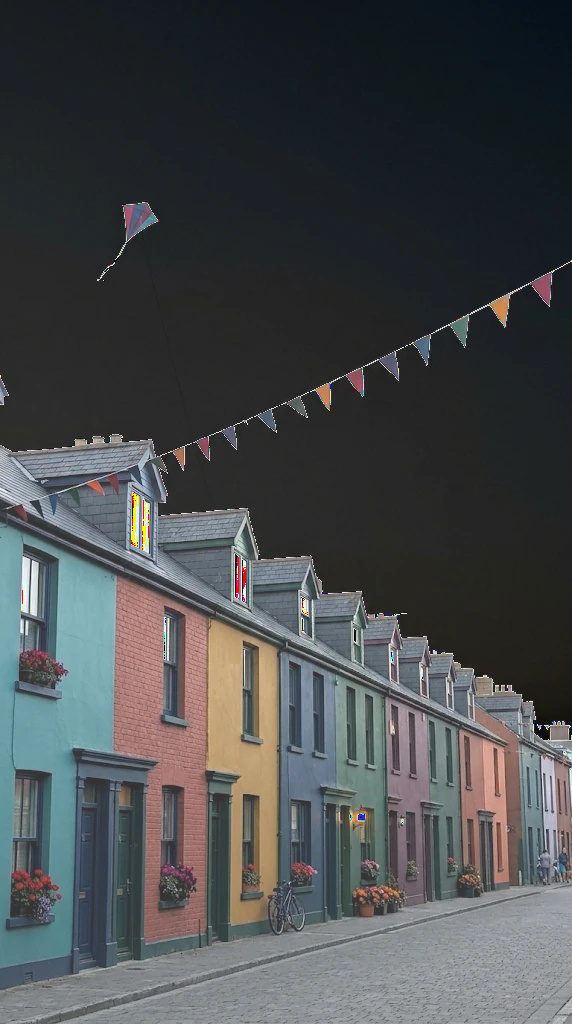

In [3]:
brighter = photo + 50
PIL.Image.fromarray(brighter)


The sky is gone.

No exception. No warning. No overflow flag. The array came back the same shape
and the same dtype it went in as, and more than half of it is wrong.


## What actually happened


In [4]:
lum = photo.max(axis=2)
wrapped = brighter.max(axis=2) < lum

print("pixels in the photo ", lum.size)
print("pixels that darkened", int(wrapped.sum()))
print("...which is         ", f"{wrapped.mean():.0%} of the photo")


pixels in the photo  585728
pixels that darkened 316708
...which is          54% of the photo


The sky is not one value, so take the one it holds most often:


In [5]:
sky = lum[lum > 205]
vals, counts = np.unique(sky, return_counts=True)
mode = int(vals[counts.argmax()])

print("most common sky value", mode, f"({counts.max()} pixels)")
print(mode, "+ 50              ", mode + 50)
print(mode + 50, "- 256             ", mode + 50 - 256)


most common sky value 242 (37384 pixels)
242 + 50               292
292 - 256              36


A byte counts 0 to 255, then starts again. 292 does not fit, so it keeps
counting from zero and lands on 36. The brightest part of the photo became
one of the darkest.

The pixels that were already dark were never in danger:


In [6]:
print("darkest pixel       ", int(lum.min()))
print("...after + 50       ", int(brighter.max(axis=2).ravel()[lum.argmin()]))


darkest pixel        0
...after + 50        50


Which is why the bug ships. The shadows look right, so the photo still looks
like a photo.


## The fix


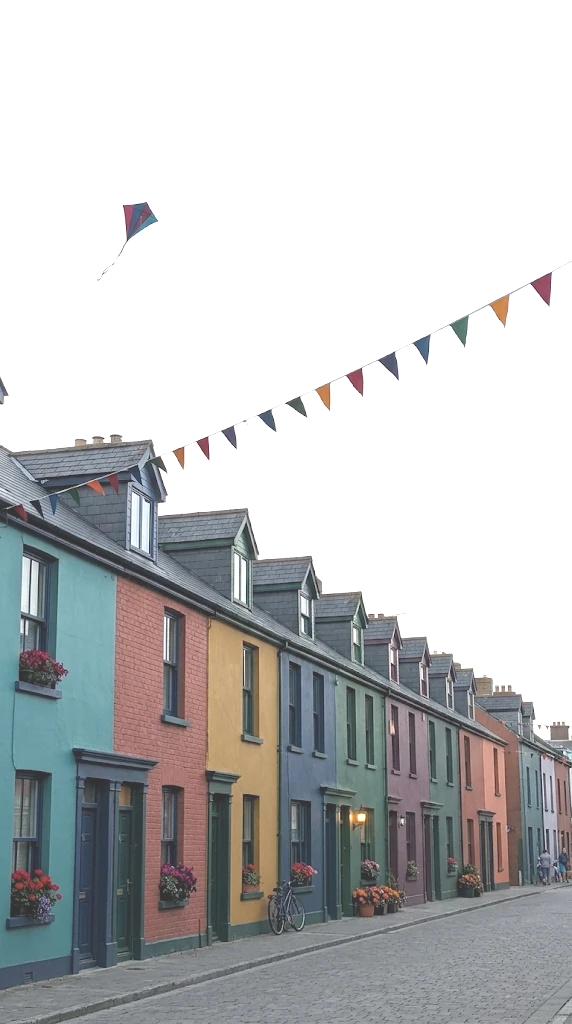

In [7]:
fixed = np.clip(photo.astype(np.int16) + 50, 0, 255).astype(np.uint8)
PIL.Image.fromarray(fixed)


In [8]:
print("nothing went darker ", bool((fixed.max(axis=2) >= lum).all()))
print("the sky stays       ", int(fixed.max()))
print("dtype back to       ", fixed.dtype)


nothing went darker  True
the sky stays        255
dtype back to        uint8


Widen the type so the sum has room, add, clip at 255, come back to `uint8`.

The same three steps work for any small integer dtype, not just images.


## One thing that trips people up

NumPy *does* warn — but only on a scalar, never on the array:


In [9]:
import warnings

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    _ = photo + 50
print("warnings on the photo :", len(caught))

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    _ = np.uint8(255) + np.uint8(1)
print("warnings on a scalar  :", len(caught), "-", caught[0].message if caught else "")


warnings on the photo : 0
warnings on a scalar  : 1 - overflow encountered in scalar add


So if you tested this in a REPL with `np.uint8(255) + 1` and saw a
`RuntimeWarning`, that is the scalar path. A photo is an array, and the array
path is silent.

---

[@therestiscode](https://youtube.com/@therestiscode)
